========== DATASET OVERVIEW ==========
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  

Dataset Shape: (20640, 10)

Dataset

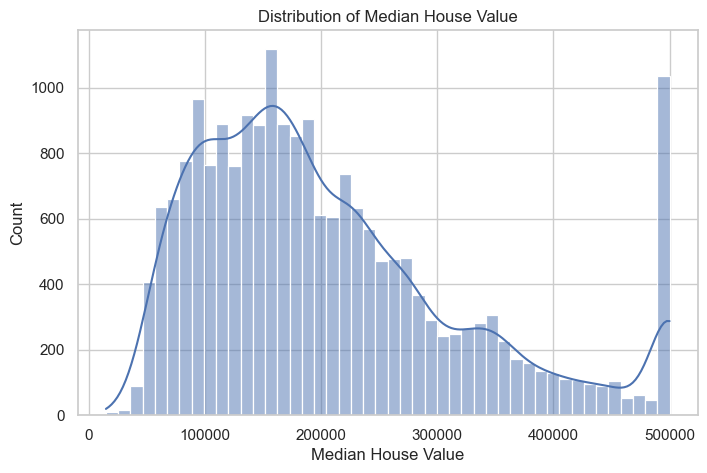

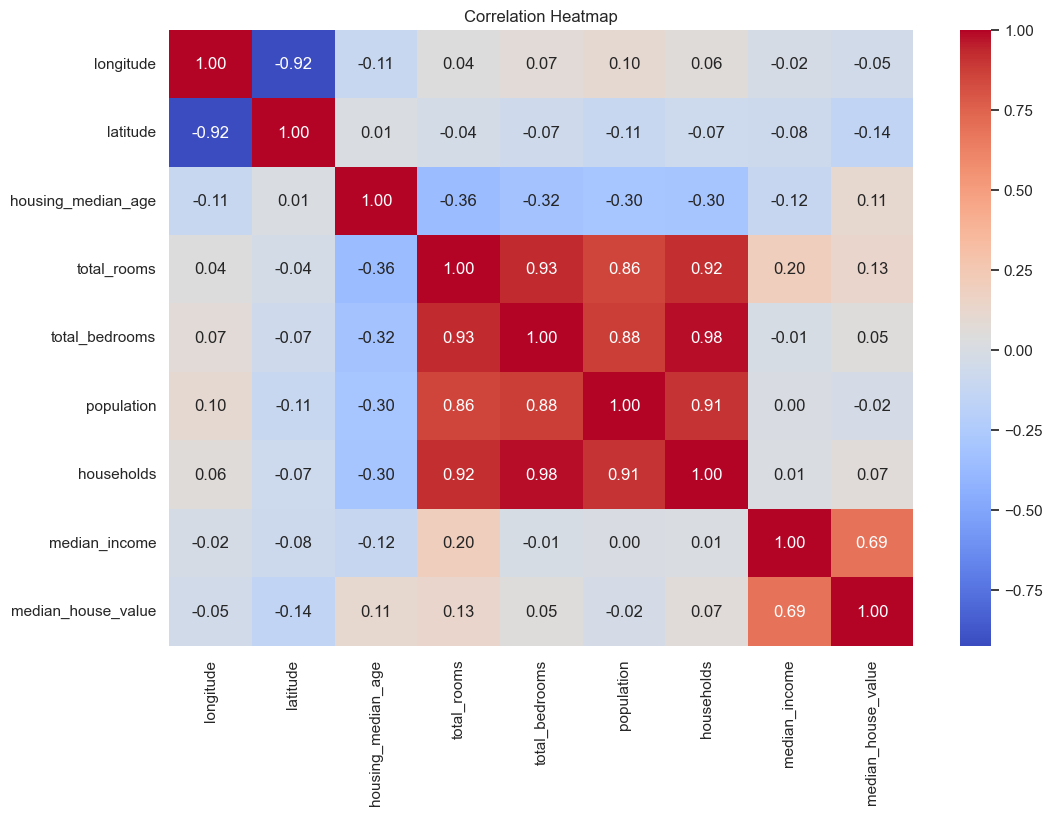


Training Shape: (16512, 9)
Testing Shape: (4128, 9)

========== FEATURE ENGINEERING ==========
       longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
14196    -117.03     32.71                33.0       3126.0           627.0   
8267     -118.16     33.77                49.0       3382.0           787.0   
17445    -120.48     34.66                 4.0       1897.0           331.0   
14265    -117.11     32.69                36.0       1421.0           367.0   
2271     -119.80     36.78                43.0       2382.0           431.0   

       population  households  median_income ocean_proximity  \
14196      2300.0       623.0         3.2596      NEAR OCEAN   
8267       1314.0       756.0         3.8125      NEAR OCEAN   
17445       915.0       336.0         4.1563      NEAR OCEAN   
14265      1418.0       355.0         1.9425      NEAR OCEAN   
2271        874.0       380.0         3.5542          INLAND   

       rooms_per_household  bedrooms_per_roo

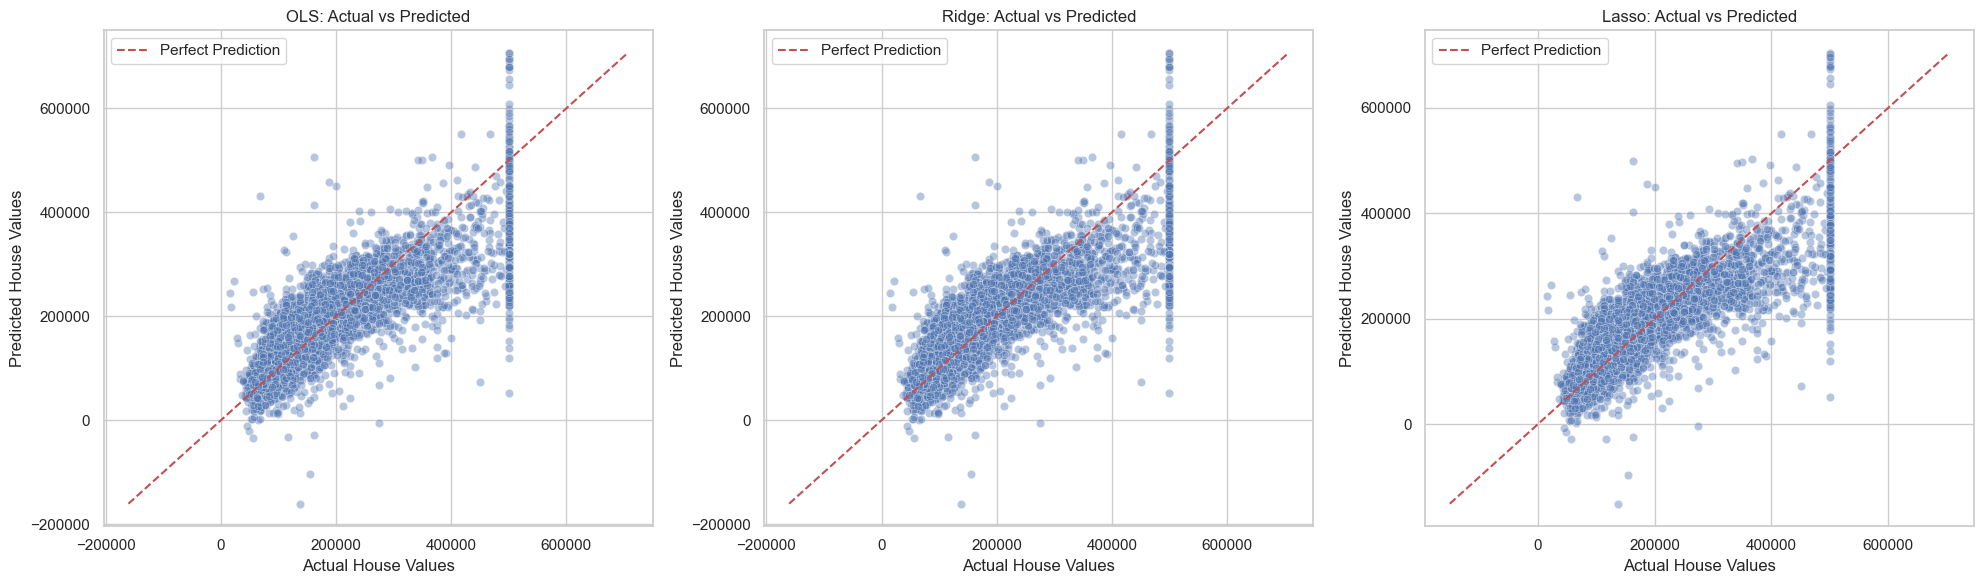

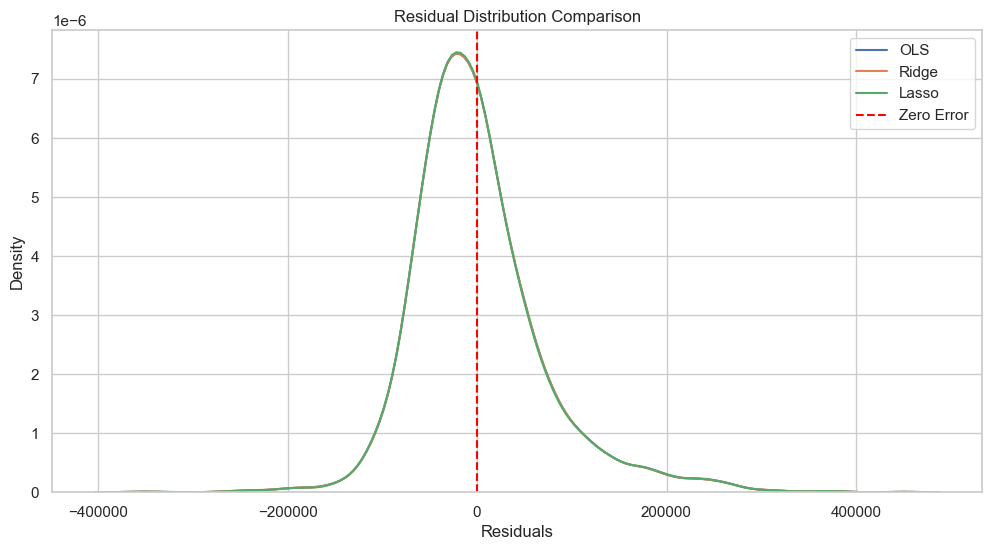

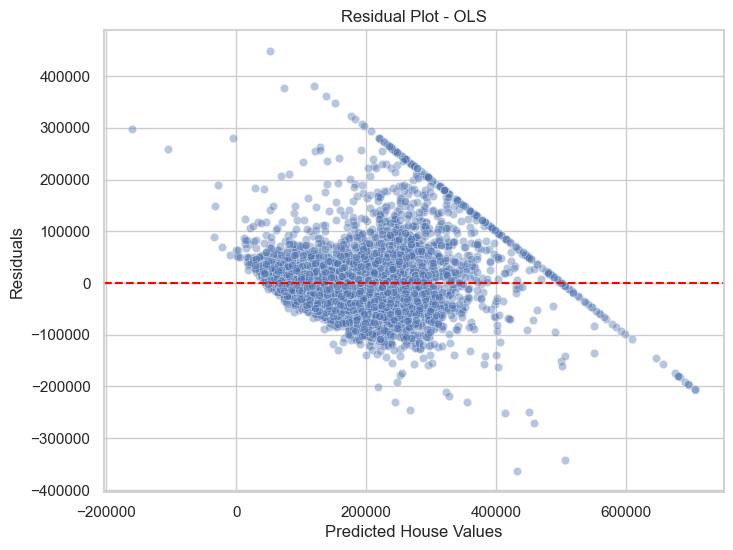


========== ACTUAL VS PREDICTED VALUES ==========
   Actual Values  Predicted Values      Residuals
0        47700.0      34725.550651   12974.449349
1        45800.0     135140.566045  -89340.566045
2       500001.0     267218.448173  232782.551827
3       218600.0     289877.067781  -71277.067781
4       278000.0     264844.134990   13155.865010

========== RESIDUAL RANGE ==========
Minimum Residual: -363857.3376462405
Maximum Residual: 448073.12270547706

========== FINAL CONCLUSION ==========
Best Model based on RMSE: OLS
Best Model based on MAE: Lasso
Best Model based on R2 Score: OLS

Selected Model for Prediction: OLS

Project Completed Successfully!


In [3]:

# ============================================================
# CALIFORNIA HOUSING PRICE PREDICTION
# DATHEON MACHINE LEARNING INTERNSHIP - TASK 2
# Complete Machine Learning Pipeline
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")


# ============================================================
# 2. LOAD DATASET
# ============================================================

df = pd.read_csv("california_house.csv")

print("========== DATASET OVERVIEW ==========")

print(df.head())
print("\nDataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())


# ============================================================
# 3. EXPLORATORY DATA ANALYSIS
# ============================================================

# Target variable distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    df['median_house_value'],
    kde=True
)

plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value")
plt.show()


# Correlation heatmap

plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()


# ============================================================
# 4. SEPARATE FEATURES AND TARGET
# ============================================================

X = df.drop('median_house_value', axis=1)

y = df['median_house_value']


# ============================================================
# 5. TRAIN TEST SPLIT
# ============================================================

x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)


# ============================================================
# 6. FEATURE ENGINEERING
# ============================================================

def create_features(data):

    data = data.copy()

    data['rooms_per_household'] = (
        data['total_rooms'] / data['households'].replace(0, np.nan)
    )

    data['bedrooms_per_room'] = (
        data['total_bedrooms'] / data['total_rooms'].replace(0, np.nan)
    )

    data['population_per_household'] = (
        data['population'] / data['households'].replace(0, np.nan)
    )

    return data


x_train = create_features(x_train)
x_test = create_features(x_test)

print("\n========== FEATURE ENGINEERING ==========")

print(x_train.head())


# ============================================================
# 7. HANDLE MISSING VALUES
# ============================================================

# Separate numerical and categorical columns

num_col = x_train.select_dtypes(
    include=np.number
).columns.tolist()

cat_col = ['ocean_proximity']


# Median imputation for numerical features

imputer = SimpleImputer(strategy='median')

x_train[num_col] = imputer.fit_transform(
    x_train[num_col]
)

x_test[num_col] = imputer.transform(
    x_test[num_col]
)


print("\n========== MISSING VALUES AFTER IMPUTATION ==========")

print(x_train.isnull().sum())


# ============================================================
# 8. MULTICOLLINEARITY ANALYSIS - VIF
# ============================================================

# VIF is calculated on numerical training features only.
# Add a constant to account for the intercept.

vif_features = num_col.copy()


def calculate_vif(data):

    vif_input = add_constant(data, has_constant='add')

    vif_data = pd.DataFrame()

    vif_data['Feature'] = vif_input.columns

    vif_data['VIF'] = [
        variance_inflation_factor(
            vif_input.values, i
        )
        for i in range(vif_input.shape[1])
    ]

    return vif_data[vif_data['Feature'] != 'const'].sort_values(
        by='VIF',
        ascending=False
    )


print("\n========== INITIAL VIF ANALYSIS ==========")

vif_initial = calculate_vif(
    x_train[vif_features]
)

print(vif_initial)


# Iteratively remove the feature with the highest VIF
# until all remaining features have VIF <= 10.

while True:

    vif_data = calculate_vif(
        x_train[vif_features]
    )

    highest_vif = vif_data.iloc[0]['VIF']

    if highest_vif <= 10:
        break

    feature_to_remove = vif_data.iloc[0]['Feature']

    print(
        f"\nRemoving {feature_to_remove} "
        f"because VIF = {highest_vif:.2f}"
    )

    vif_features.remove(feature_to_remove)


print("\n========== FINAL VIF ANALYSIS ==========")

final_vif = calculate_vif(
    x_train[vif_features]
)

print(final_vif)

print("\nSelected Numerical Features:")
print(vif_features)


# ============================================================
# 9. PREPROCESSING
# IMPUTATION + SCALING + ONE HOT ENCODING
# ============================================================

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])


preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, vif_features),
    ('cat', categorical_pipeline, cat_col)
])


# ============================================================
# 10. OLS REGRESSION
# ============================================================

model_ols = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', LinearRegression())
])

model_ols.fit(x_train, y_train)

y_pred_ols = model_ols.predict(x_test)


# ============================================================
# 11. RIDGE REGRESSION + GRIDSEARCHCV
# ============================================================

ridge_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('ridge', Ridge())
])


ridge_params = {
    'ridge__alpha': [0.01, 0.1, 1, 10, 100, 1000]
}


ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)


ridge_grid.fit(x_train, y_train)

best_ridge = ridge_grid.best_estimator_

y_pred_ridge = best_ridge.predict(x_test)


print("\n========== RIDGE RESULTS ==========")

print("Best Ridge Parameters:", ridge_grid.best_params_)

print("Best Ridge CV RMSE:", -ridge_grid.best_score_)


# ============================================================
# 12. LASSO REGRESSION + GRIDSEARCHCV
# TARGET SCALING
# ============================================================

lasso_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('lasso', Lasso(
        max_iter=100000,
        tol=0.001
    ))
])


# Target scaling is performed internally.
# Predictions are automatically converted back
# to the original house-value scale.

lasso_model = TransformedTargetRegressor(
    regressor=lasso_pipeline,
    transformer=StandardScaler()
)


lasso_params = {
    'regressor__lasso__alpha': [
        0.001, 0.01, 0.1, 1, 10, 100
    ]
}


lasso_grid = GridSearchCV(
    estimator=lasso_model,
    param_grid=lasso_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)


lasso_grid.fit(x_train, y_train)

best_lasso = lasso_grid.best_estimator_

y_pred_lasso = best_lasso.predict(x_test)


print("\n========== LASSO RESULTS ==========")

print("Best Lasso Parameters:", lasso_grid.best_params_)

print("Best Lasso CV RMSE:", -lasso_grid.best_score_)


# ============================================================
# 13. MODEL EVALUATION
# ============================================================

def evaluate_model(y_true, y_pred, model_name):

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mae = mean_absolute_error(
        y_true, y_pred
    )

    r2 = r2_score(
        y_true, y_pred
    )

    print(f"\n{model_name}")

    print("RMSE:", round(rmse, 2))
    print("MAE:", round(mae, 2))
    print("R2 Score:", round(r2, 4))


print("\n========== MODEL EVALUATION ==========")

evaluate_model(y_test, y_pred_ols, "OLS Regression")

evaluate_model(y_test, y_pred_ridge, "Ridge Regression")

evaluate_model(y_test, y_pred_lasso, "Lasso Regression")


# ============================================================
# 14. MODEL COMPARISON
# ============================================================

results = pd.DataFrame({

    'Model': ['OLS', 'Ridge', 'Lasso'],

    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_ols)),
        np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
        np.sqrt(mean_squared_error(y_test, y_pred_lasso))
    ],

    'MAE': [
        mean_absolute_error(y_test, y_pred_ols),
        mean_absolute_error(y_test, y_pred_ridge),
        mean_absolute_error(y_test, y_pred_lasso)
    ],

    'R2 Score': [
        r2_score(y_test, y_pred_ols),
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso)
    ]

})


print("\n========== MODEL COMPARISON ==========")

print(
    results.sort_values(
        by='RMSE'
    ).to_string(index=False)
)


# ============================================================
# 15. BEST MODEL SELECTION
# ============================================================

predictions = {

    'OLS': y_pred_ols,

    'Ridge': y_pred_ridge,

    'Lasso': y_pred_lasso

}


best_model_name = results.loc[
    results['RMSE'].idxmin(),
    'Model'
]


best_predictions = predictions[best_model_name]


print("\n========== BEST MODEL ==========")

print("Best Model:", best_model_name)

print(
    "Lowest RMSE:",
    round(results['RMSE'].min(), 2)
)


# ============================================================
# 16. ACTUAL VS PREDICTED PLOTS
# ALL THREE MODELS
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 6)
)

model_predictions = [
    ('OLS', y_pred_ols),
    ('Ridge', y_pred_ridge),
    ('Lasso', y_pred_lasso)
]


for ax, (name, prediction) in zip(
    axes, model_predictions
):

    sns.scatterplot(
        x=y_test,
        y=prediction,
        alpha=0.4,
        ax=ax
    )

    # Perfect prediction reference line

    min_value = min(y_test.min(), prediction.min())
    max_value = max(y_test.max(), prediction.max())

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        'r--',
        label='Perfect Prediction'
    )

    ax.set_title(f'{name}: Actual vs Predicted')

    ax.set_xlabel("Actual House Values")

    ax.set_ylabel("Predicted House Values")

    ax.legend()


plt.tight_layout()

plt.show()


# ============================================================
# 17. RESIDUAL DISTRIBUTION COMPARISON
# ALL THREE MODELS
# ============================================================

residuals_ols = y_test - y_pred_ols

residuals_ridge = y_test - y_pred_ridge

residuals_lasso = y_test - y_pred_lasso


plt.figure(figsize=(12, 6))


sns.kdeplot(
    residuals_ols,
    label='OLS',
    fill=False
)

sns.kdeplot(
    residuals_ridge,
    label='Ridge',
    fill=False
)

sns.kdeplot(
    residuals_lasso,
    label='Lasso',
    fill=False
)


plt.axvline(
    x=0,
    color='red',
    linestyle='--',
    label='Zero Error'
)


plt.title("Residual Distribution Comparison")

plt.xlabel("Residuals")

plt.ylabel("Density")

plt.legend()

plt.show()


# ============================================================
# 18. RESIDUAL SCATTER PLOT
# BEST MODEL
# ============================================================

best_residuals = y_test - best_predictions


plt.figure(figsize=(8, 6))


sns.scatterplot(
    x=best_predictions,
    y=best_residuals,
    alpha=0.4
)


plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)


plt.xlabel("Predicted House Values")

plt.ylabel("Residuals")

plt.title(f"Residual Plot - {best_model_name}")

plt.show()


# ============================================================
# 19. ACTUAL AND PREDICTED VALUES
# ============================================================

comparison = pd.DataFrame({

    'Actual Values': y_test.values,

    'Predicted Values': best_predictions

})


comparison['Residuals'] = (
    comparison['Actual Values'] -
    comparison['Predicted Values']
)


print("\n========== ACTUAL VS PREDICTED VALUES ==========")

print(comparison.head())


print("\n========== RESIDUAL RANGE ==========")

print("Minimum Residual:", comparison['Residuals'].min())

print("Maximum Residual:", comparison['Residuals'].max())


# ============================================================
# 20. FINAL MODEL CONCLUSION
# ============================================================

best_rmse_model = results.loc[
    results['RMSE'].idxmin(), 'Model'
]

best_mae_model = results.loc[
    results['MAE'].idxmin(), 'Model'
]

best_r2_model = results.loc[
    results['R2 Score'].idxmax(), 'Model'
]


print("\n========== FINAL CONCLUSION ==========")

print("Best Model based on RMSE:", best_rmse_model)

print("Best Model based on MAE:", best_mae_model)

print("Best Model based on R2 Score:", best_r2_model)

print(
    "\nSelected Model for Prediction:",
    best_model_name
)

print("\nProject Completed Successfully!")


## Conclusion

In this project, I developed a California Housing Price Prediction model using three regression algorithms: Ordinary Least Squares (OLS), Ridge Regression, and Lasso Regression.

The dataset was preprocessed using median imputation, feature engineering, One-Hot Encoding, and StandardScaler. Multicollinearity was analyzed using Variance Inflation Factor (VIF), and highly correlated numerical features were removed.

GridSearchCV was used to optimize the regularization parameters for Ridge and Lasso Regression.

### Model Performance

- **OLS Regression:** RMSE = 70,308.83, MAE = 50,594.98, R² = 0.6228.
- **Ridge Regression:** RMSE = 70,315.07, MAE = 50,600.56, R² = 0.6227.
- **Lasso Regression:** RMSE = 70,337.16, MAE = 50,587.86, R² = 0.6225.

### Final Observation

OLS Regression achieved the lowest RMSE and highest R² score, making it the selected model for this experiment. Lasso Regression achieved the lowest MAE.

The results indicate that regularization did not provide a significant performance improvement over OLS for this particular dataset and feature configuration.

This project helped demonstrate the practical application of feature engineering, multicollinearity analysis, regularization, hyperparameter tuning, and regression model evaluation.